In [370]:
#그래프관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler


In [371]:
# 데이터 전처리 완료
perch_length = np.array(
    [8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0,
    21.0, 21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5,
    22.5, 22.7, 23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5,
    27.3, 27.5, 27.5, 27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0,
    36.5, 36.0, 37.0, 37.0, 39.0, 39.0, 39.0, 40.0, 40.0, 40.0,
    40.0, 42.0, 43.0, 43.0, 43.5, 44.0]
    )
perch_weight = np.array(
    [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
    110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
    197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
    820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
    1000.0, 1000.0]
    )

In [372]:
# 학습데이터 , 테스트데이터 분리
train_data,test_data,train_label,test_label = train_test_split(perch_length,perch_weight)

In [373]:
train_data = train_data.reshape(-1,1)
test_data = test_data.reshape(-1,1)

In [374]:
# 데이터 학습
lr = LinearRegression()
lr.fit(train_data,train_label)
# 데이터 예측
predict = lr.predict(test_data)
print('무게예측 : ',predict)
# 정확도
score = lr.score(train_data,train_label)
score2 = lr.score(test_data,test_label)
print('train 정확도 : ',score)
print('test 정확도 : ',score2)

#기울기,y절편 - LinearRegression() 사용할때 나타남.
print('기울기 : ',lr.coef_)
print('y절편 : ',lr.intercept_)

무게예측 :  [ 99.321035   172.37721931  84.70979814 939.46715451  51.8345152
 172.37721931 939.46715451 793.3547859  190.64126538 197.94688381
 -39.48571518 281.96149577 365.97610772 391.54577222]
train 정확도 :  0.911750918200726
test 정확도 :  0.9354659745766148
기울기 :  [36.52809215]
y절편 :  -631.2408080525065


In [375]:
# KNeighborsRegressor 50센치 - 1000그람 예측
# 50센치 농어 예측 - 1132
# 100센치 농어 예측 - 3000
predict2 = lr.predict([[100]])
print('예측무게 : ',predict2)



예측무게 :  [3021.56840722]


In [383]:
#길이를 입력받아 , 무게를 예측하고 , 산점도 그래프에 표시하시오.
#농어 길이를 입력하세요. 예) 52
#예측무게 : 1230
#산점도 그래프에 표시
#선 그래프도 함께 표시
input1 = input('농어길이를 입력하시오 : 예) 42 ')
input1 = float(input1)
predict = lr.predict([[input1]])
print('예측무게 : ',predict)

예측무게 :  [-448.60034729]


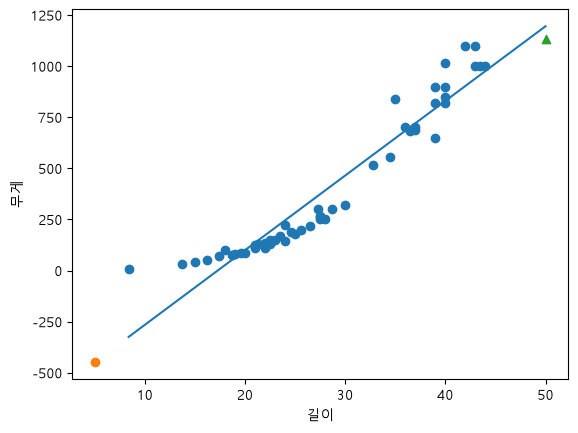

In [384]:
# 산점도 그래프

plt.scatter(perch_length,perch_weight)
plt.scatter(input1,predict)
plt.scatter(50,1132,marker='^')
# plt.scatter(100,3000,marker='D')
plt.plot([8.4,50],[8.4*lr.coef_+lr.intercept_,50*lr.coef_+lr.intercept_]) # 선그래프 
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()